In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OrdinalEncoder
import os

In [4]:
 sales = pd.read_parquet('/content/done_sales.parquet')
 prices = pd.read_parquet('/content/done_prices.parquet')
 calendar = pd.read_parquet('/content/done_cal.parquet')

## 🔍 Tạo đặc trưng thời gian từ dữ liệu demand

Để mô hình dự đoán chính xác hơn, ta tạo ra các đặc trưng từ dữ liệu quá khứ, đồng thời mong muốn học được món hàng đang được dự đoán có đang nằm gần hoặc trong xu hướng hay không:

- **Lag features**: Doanh thu tại các mốc thời gian lùi lại, ví dụ 7 hoặc 28 ngày trước. Điều này giúp mô hình nhận biết chu kỳ tuần / tháng.
- **Rolling mean features**: Trung bình động trong 7 hoặc 28 ngày gần mốc lag, giúp mô hình hiểu xu hướng tăng giảm của nhu cầu.
- Tất cả đặc trưng đều được tính theo từng `id` (mỗi sản phẩm tại từng cửa hàng cụ thể).

Hàm `demand_features(df)` sẽ tự động tạo ra các cột này để sử dụng trong huấn luyện mô hình.

Để hiểu rõ hơn ví dụ nếu như là lag_t7 cho ngày thứ 100 của món hàng A sẽ là doanh thu của ngày thứ 93. còn, rolling_mean_lag7_w28 của ngày thứ 100 của món hàng A sẽ là doanh thu trung bình từ ngày 72 (=100 - 28) tới ngày 78 (7 ngày).


In [8]:
from sklearn.model_selection import train_test_split
import lightgbm as lgb
LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """

    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")

    return df

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")

    return out.reset_index()

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """

    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))

    # Add demand features
    df = demand_features(df)

    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]

    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)

    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1

    # Determine list of covariables
    x = list(set(df.columns) - {'id', 'd', 'demand'})

    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    return df, test, x

In [9]:
df, test, x = prep_data(sales, 1000 - 28)

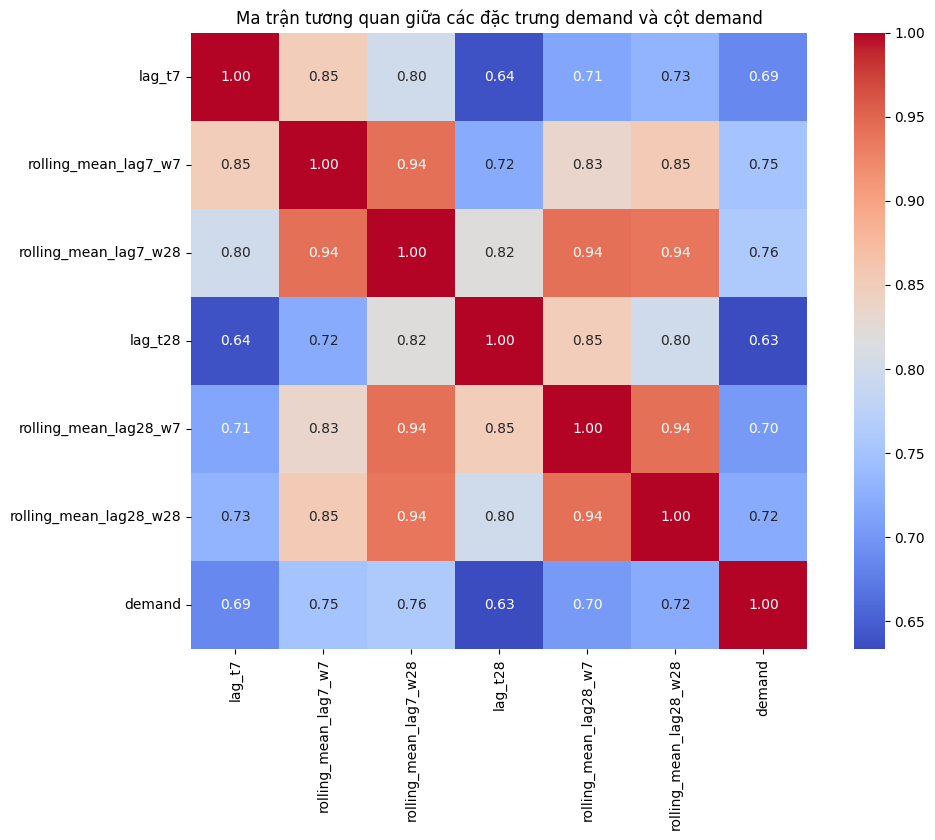

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_demand_feature_correlation(df):
    # Lấy danh sách các cột được tạo bởi demand_features
    demand_cols = [col for col in df.columns if col.startswith("lag_t") or col.startswith("rolling_mean")]

    # Thêm cột demand để so sánh tương quan
    corr_cols = demand_cols + ["demand"]

    # Loại bỏ hàng có NaN (do shift và rolling tạo ra)
    df_corr = df[corr_cols].dropna()

    # Tính ma trận tương quan
    corr = df_corr.corr()

    # Vẽ heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
    plt.title("Ma trận tương quan giữa các đặc trưng demand và cột demand")
    plt.show()
plot_demand_feature_correlation(df)


## Nhận xét ma trận tương quan
Thông qua, ma trận dễ dàng thấy demand ảnh hưởng khá nhiều bởi các feature đã được tạo ra. Tuy nhiên, cũng có thể thấy các cột rolling_mean có độ tương quan cao khi bắt cặp với nhau.

Dựa trên, độ tương quan giữa demand và các cột rolling_mean, nhóm quyết định giữ lại rolling_mean_lag7_w7 và rolling_mean_lag7_w28 và xóa đi 2 rolling_mean còn lại vì có độ tương quan cao với 2 rolling_mean_lag7_w7 còn lại

In [ ]:
df.drop(['rolling_mean_lag7_w7', 'rolling_mean_lag7_w28'], axis=1, inplace=True)

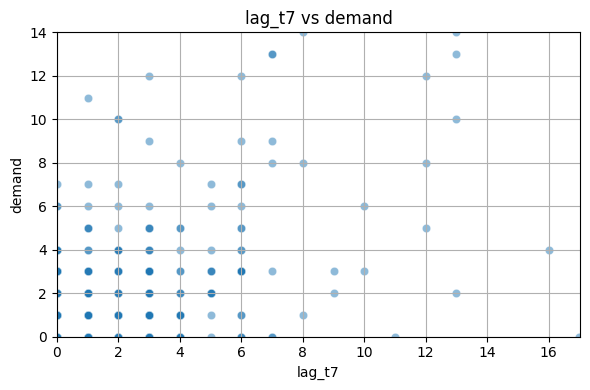

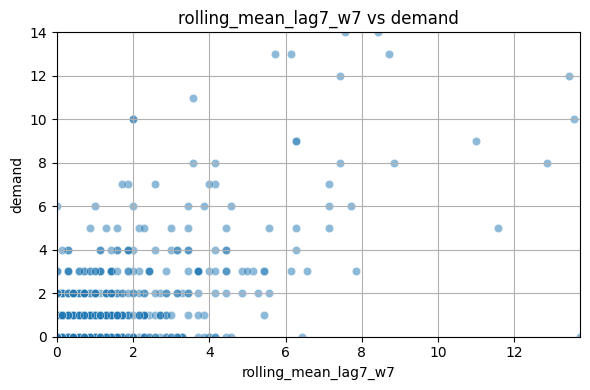

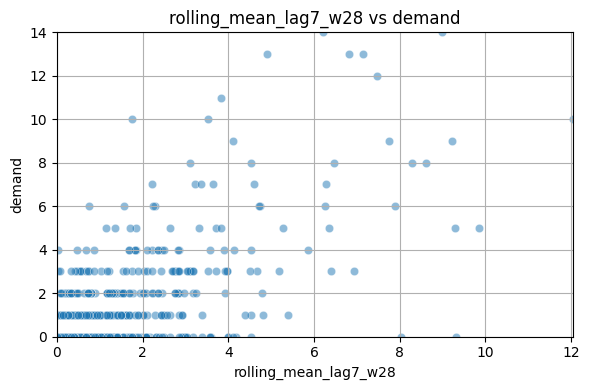

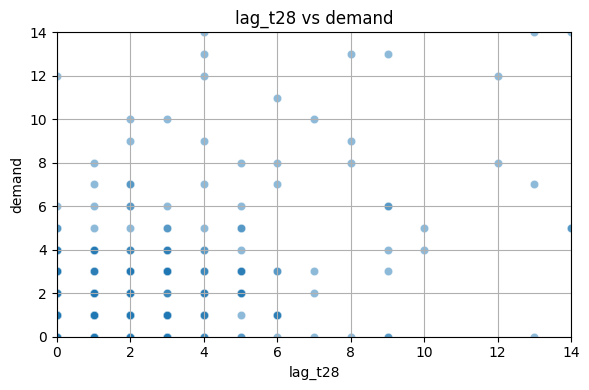

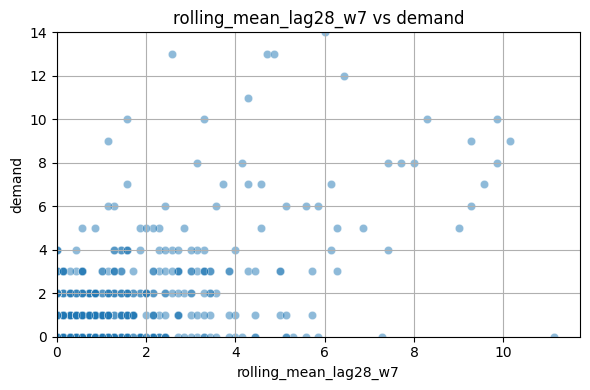

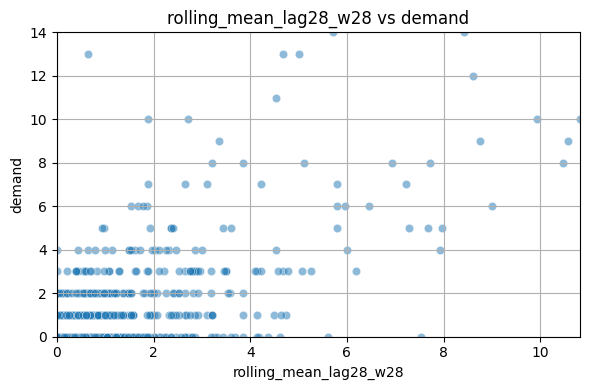

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_demand_feature_scatter(df, sample_size=1000, use_log=False, clip_outliers=True):
    import seaborn as sns
    import matplotlib.pyplot as plt

    demand_cols = [col for col in df.columns if col.startswith("lag_t") or col.startswith("rolling_mean")]
    df_sample = df[demand_cols + ["demand"]].dropna().sample(n=sample_size, random_state=42)

    for col in demand_cols:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=df_sample, x=col, y="demand", alpha=0.5)

        if clip_outliers:
            plt.xlim(df_sample[col].quantile(0.01), df_sample[col].quantile(0.99))
            plt.ylim(df_sample["demand"].quantile(0.01), df_sample["demand"].quantile(0.99))

        if use_log:
            plt.xscale("log")
            plt.yscale("log")

        plt.title(f"{col} vs demand")
        plt.xlabel(col)
        plt.ylabel("demand")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

plot_demand_feature_scatter(df)


In [2]:
df = pd.read_parquet('/content/train_val (1).parquet').head(1000000)
print(df.columns)

Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag', 'flag_ufc', 'humidity', 'gold_price'],
      dtype='object')


In [5]:
print(df['gold_price'])

0         1,244.10
1         1,244.10
2         1,244.10
3         1,244.10
4         1,244.10
            ...   
999995    1,203.30
999996    1,203.30
999997    1,203.30
999998    1,203.30
999999    1,203.30
Name: gold_price, Length: 1000000, dtype: object


In [3]:
import pandas as pd
import numpy as np

# Hàm thay thế NaN trong gold_price bằng trung bình 7 ngày trước đó
def fill_gold_price_with_rolling_mean(df):
    df = df.copy()
    df['gold_price'] = pd.to_numeric(df['gold_price'].str.replace(',', ''), errors='coerce')

    for i in range(len(df)):
        if pd.isna(df.loc[i, 'gold_price']):
                df.loc[i, 'gold_price'] = df.loc[i-1, 'gold_price']  # Gán trực tiếp vào cột gold_price

    return df

# Gọi hàm
df = fill_gold_price_with_rolling_mean(df)

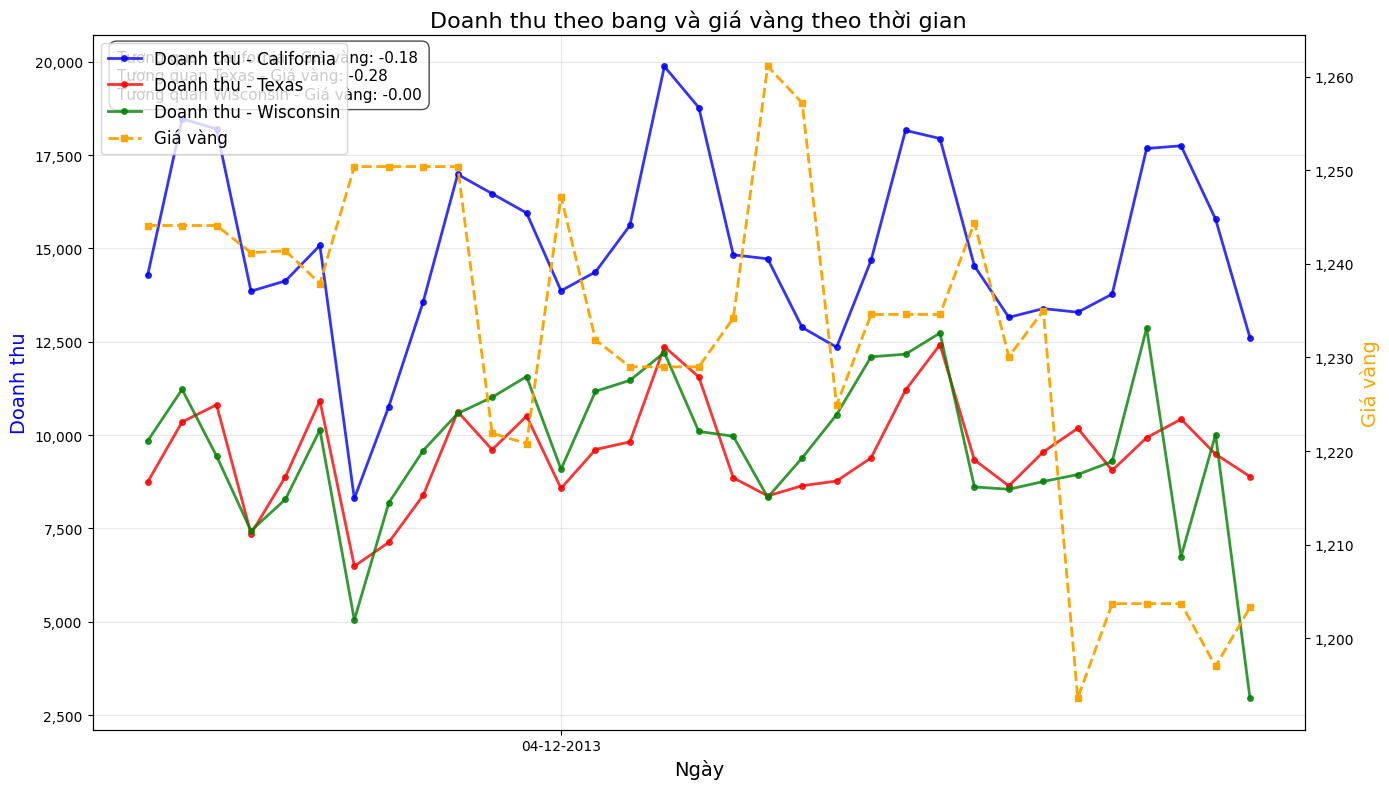

In [5]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plt
# Giả sử df là DataFrame của bạn đã có sẵn
# Nếu cần, hãy thay thế phần này bằng code để đọc dữ liệu của bạn
# df = pd.read_csv('đường_dẫn_đến_file.csv')

# Chuyển đổi state_id sang tên bang
state_mapping = {
    1: 'California',
    2: 'Texas',
    3: 'Wisconsin'
}

# Thêm cột state_name vào DataFrame
df['state_name'] = df['state_id'].map(state_mapping)

# Chuyển đổi cột ngày sang định dạng datetime nếu chưa phải
df['date'] = pd.to_datetime(df['date'])

# Nhóm dữ liệu theo ngày và bang, tính tổng doanh thu cho tất cả sản phẩm
daily_revenue_by_state = df.groupby(['date', 'state_name'])['demand'].sum().unstack()

# Lấy giá vàng cho mỗi ngày (giả sử giá vàng giống nhau trong một ngày)
gold_prices = df.groupby('date')['gold_price'].first()

# Tạo một figure với 2 trục y
fig, ax1 = plt.subplots(figsize=(14, 8))

# Đặt trục y thứ hai cho giá vàng
ax2 = ax1.twinx()

# Màu sắc cho các đường doanh thu của từng bang
colors = ['blue', 'red', 'green']

# Vẽ đường doanh thu cho mỗi bang trên trục y thứ nhất
for i, state in enumerate(daily_revenue_by_state.columns):
    ax1.plot(
        daily_revenue_by_state.index,
        daily_revenue_by_state[state],
        color=colors[i],
        marker='o',
        markersize=4,
        linewidth=2,
        alpha=0.8,
        label=f'Doanh thu - {state}'
    )

# Vẽ đường giá vàng trên trục y thứ hai
ax2.plot(
    gold_prices.index,
    gold_prices.values,
    color='orange',
    marker='s',
    markersize=4,
    linewidth=2,
    linestyle='--',
    label='Giá vàng'
)

# Định dạng trục x để hiển thị label cứ mỗi 50 ngày
# Xác định ngày đầu tiên và cuối cùng trong dữ liệu
first_date = min(daily_revenue_by_state.index.min(), gold_prices.index.min())
last_date = max(daily_revenue_by_state.index.max(), gold_prices.index.max())

# Tạo một mảng các ngày với khoảng cách 50 ngày
date_range = pd.date_range(start=first_date, end=last_date, freq='50D')

# Thiết lập các vị trí và nhãn cho trục x
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=50))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))

# Đặt tiêu đề và nhãn
ax1.set_title('Doanh thu theo bang và giá vàng theo thời gian', fontsize=16)
ax1.set_xlabel('Ngày', fontsize=14)
ax1.set_ylabel('Doanh thu', fontsize=14, color='blue')
ax2.set_ylabel('Giá vàng', fontsize=14, color='orange')

# Xoay nhãn trục x để dễ đọc
plt.xticks(rotation=45)

# Định dạng số lớn hơn với dấu phẩy ngăn cách hàng nghìn
def thousands_formatter(x, pos):
    return f'{int(x):,}'

ax1.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax2.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# Kết hợp legends từ cả hai trục
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, fontsize=12)

# Thêm lưới để dễ đọc
ax1.grid(True, alpha=0.3)

# Tính tương quan giữa giá vàng và doanh thu cho mỗi bang và hiển thị
corr_text = []
for state in daily_revenue_by_state.columns:
    # Kết hợp dữ liệu để tính toán tương quan
    state_data = pd.DataFrame({
        'revenue': daily_revenue_by_state[state],
        'gold_price': gold_prices
    }).dropna()

    corr = state_data['revenue'].corr(state_data['gold_price'])
    corr_text.append(f'Tương quan {state} - Giá vàng: {corr:.2f}')

# Hiển thị thông tin tương quan ở góc trái trên
ax1.annotate(
    '\n'.join(corr_text),
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='left',
    fontsize=11,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
)

plt.tight_layout()
plt.show()